# Telco Customer Churn — Churn Risk Model

**Author:** Hayagriva Boodhoo

An end-to-end machine learning project: a churn-risk scoring model for a telecom retention team, from business framing through exploration, preparation, modelling, evaluation and a deployable scoring script.

### Contents

1. Business Framing
2. Data Exploration
3. Data Preparation
4. Modelling
5. Evaluation & Diagnosis
6. Deployment Readiness

A business-audience write-up is in `report/business_report.pdf`.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from typing import List, Tuple, Dict, Any

RANDOM_STATE: int = 42  # fixed everywhere a stochastic process occurs, for reproducibility

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_columns", 30)


## 1. Business Framing

### 1.1 The problem, in one paragraph

A telecom operator's customer retention team has a limited monthly budget for retention outreach
(calls, targeted discounts, proactive support) and currently spends it either reactively — after a
customer has already initiated cancellation, when it's usually too late — or indiscriminately
across large customer segments, wasting most of it on customers who were never going to leave.
This project builds a binary classifier that scores each active customer's probability of
cancelling ("churning") in the near future, using their account and service data, so the retention
team can rank the customer base by risk and direct their limited budget at the customers where an
intervention is actually likely to change the outcome.

### 1.2 Who is the "user", and how does a prediction change their behaviour?

The user is the **retention team's monthly outreach planner** (a person or a scheduled process
feeding their CRM). Today, without a score, they either contact everyone active this month or wait
for a cancellation request. With the model, each month they receive a **ranked list of customers by
churn probability**; a prediction above the chosen threshold **changes their behaviour concretely**:
that customer is added to this month's proactive-contact list (a retention call, a loyalty offer,
or a contract-renewal nudge) *before* any cancellation signal exists, instead of being left alone
or contacted reactively.

### 1.3 Defining success: metric and deployment threshold

**Cost asymmetry.** Two prediction errors are possible and they are not equally costly. A **false
negative** (missed churner) means the customer leaves with zero intervention — the business loses
their full future revenue. A **false positive** (false alarm) costs only an unneeded discount or
call to someone who was staying anyway. Because a missed churner is far more expensive, the primary
metric is **Recall on the churn class**, subject to Precision not collapsing (flagging literally
everyone as high-risk would trivially maximise recall while being useless — see Section 4.5 for why
this rules out a naive baseline). **ROC-AUC** is the secondary metric, since it matches the actual
workflow — the team needs a *ranking*, not just a yes/no.

**Deployment threshold — what makes this model worth shipping:** we set the bar at
**ROC-AUC ≥ 0.75** (meaningfully, reliably better than chance — a coin flip is 0.50) **and
Recall ≥ 0.65** on held-out data (catching at least two-thirds of true churners, a level at which
the retention team's outreach starts covering a majority of the actual risk rather than a small
fraction of it). Both thresholds must be measured on a **test set the model never saw during
training** (Section 5), not on training performance, since training performance systematically
overstates real-world performance. If the model clears both bars, it is worth deploying over the
status quo (no targeting at all); if not, more feature engineering or a different problem framing
is needed before shipping. Section 5.1 checks the final model against this exact bar.


## 2. Data Exploration

### 2.1 Load and describe the data

**Dataset:** IBM Telco Customer Churn — 7,043 customers, 21 columns (19 predictive features +
customer ID + target), with both numeric and categorical features and a binary classification
target. Source and reproduction instructions are in `README.md`.


In [2]:
DATA_PATH = "../data/raw/telco_churn.csv"

df_raw = pd.read_csv(DATA_PATH)
df = df_raw.copy()  # all cleaning happens on the copy; df_raw stays untouched for comparison

print(f"Shape: {df.shape[0]} rows x {df.shape[1]} columns")
df.head()


Shape: 7043 rows x 21 columns


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

Two data-quality issues are visible immediately and are investigated properly (not just patched)
in Section 3.1: `TotalCharges` is typed as text (`object`), not numeric — this always means at
least one non-numeric value is hiding in it — and `SeniorCitizen` is stored as 0/1 while every
other Yes/No field uses the strings "Yes"/"No".

### 2.2 Descriptive statistics on every column

Numeric columns first (central tendency, dispersion, shape):


In [4]:
numeric_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
# TotalCharges cleaned here (not lost as text) purely so its numeric stats are meaningful in this
# preview; the full, justified cleaning step (with diagnosis of *why* it needs cleaning) is Section 3.1.
_preview = df.copy()
_preview["TotalCharges"] = pd.to_numeric(_preview["TotalCharges"], errors="coerce")

desc = _preview[numeric_cols].describe().T
desc["skew"] = _preview[numeric_cols].skew()
desc["kurtosis"] = _preview[numeric_cols].kurt()
desc


,count,mean,std,min,25%,50%,75%,max,skew,kurtosis
tenure,7043.0,32.371149,24.559481,0.00,9.00,29.000,55.0000,72.00,0.239540,-1.387372
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.50,70.350,89.8500,118.75,-0.220524,-1.257260
TotalCharges,7032.0,2283.300441,2266.771362,18.80,401.45,1397.475,3794.7375,8684.80,0.961642,-0.231799


`TotalCharges` mean (~2283) sits well above its median (~1397) — right-skewed, as confirmed by its
skew ≈ 1.0: a majority of customers with low cumulative spend (short tenure), and a smaller number
of long-tenured customers pulling the mean up. `tenure` and `MonthlyCharges` are closer to
symmetric. No impossible values (no negative charges, no absurd tenure) — a first, cheap
sanity check that the raw data isn't corrupted.

Now every categorical column — frequency and proportion (the mode *is* the descriptive statistic
for a non-ordinal category):


In [5]:
cat_cols = df.select_dtypes(include="object").columns.drop(["customerID", "Churn"])
for c in cat_cols:
    vc = df[c].value_counts(normalize=True).mul(100).round(1)
    print(f"--- {c} ---")
    print(vc.to_string())
    print()


--- gender ---
gender
Male      50.5
Female    49.5

--- Partner ---
Partner
No     51.7
Yes    48.3

--- Dependents ---
Dependents
No     70.0
Yes    30.0

--- PhoneService ---
PhoneService
Yes    90.3
No      9.7

--- MultipleLines ---
MultipleLines
No                  48.1
Yes                 42.2
No phone service     9.7

--- InternetService ---
InternetService
Fiber optic    44.0
DSL            34.4
No             21.7

--- OnlineSecurity ---
OnlineSecurity
No                     49.7
Yes                    28.7
No internet service    21.7

--- OnlineBackup ---
OnlineBackup
No                     43.8
Yes                    34.5
No internet service    21.7

--- DeviceProtection ---
DeviceProtection
No                     43.9
Yes                    34.4
No internet service    21.7

--- TechSupport ---
TechSupport
No                     49.3
Yes                    29.0
No internet service    21.7

--- StreamingTV ---
StreamingTV
No                     39.9
Yes                    38

TotalCharges
20.2       0.2
           0.2
19.75      0.1
19.9       0.1
20.05      0.1
19.65      0.1
45.3       0.1
19.55      0.1
20.15      0.1
19.45      0.1
20.25      0.1
20.45      0.1
20.3       0.1
74.7       0.1
70.6       0.1
44         0.1
75.3       0.1
20.4       0.1
19.85      0.1
49.9       0.1
44.4       0.1
69.9       0.1
20.35      0.1
50.15      0.1
69.6       0.1
19.5       0.1
19.2       0.1
69.95      0.1
19.3       0.1
19.4       0.1
20.5       0.1
19.95      0.1
69.65      0.1
70.45      0.0
24.8       0.0
84.5       0.0
25.25      0.0
80.55      0.0
19.25      0.0
69.55      0.0
74.35      0.0
85         0.0
45.7       0.0
74.6       0.0
35.9       0.0
220.45     0.0
20         0.0
2317.1     0.0
470.2      0.0
74.9       0.0
45.85      0.0
86.05      0.0
69.25      0.0
50.45      0.0
20.55      0.0
44.75      0.0
45.1       0.0
20.9       0.0
75.35      0.0
74.3       0.0
383.65     0.0
1284.2     0.0
85.5       0.0
70.15      0.0
50.6       0.0
305.55     0

/tmp/ipykernel_949/797535158.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes(include="object").columns.drop(["customerID", "Churn"])


Nothing here shows stray whitespace, inconsistent casing, or unexpected category values —
confirms the raw data is well-formed categorically. `SeniorCitizen` prints as `0`/`1` here since it
hasn't been relabelled yet (that happens in Section 3.1, alongside the `TotalCharges` fix).

### 2.3 Visualise the target variable's distribution


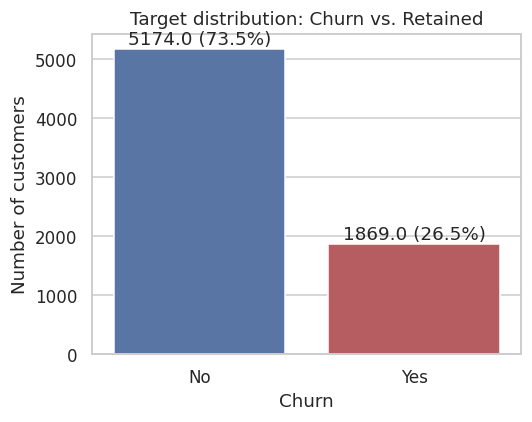

Base churn rate: 26.537%


In [6]:
fig, ax = plt.subplots(figsize=(5, 4))
sns.countplot(data=df, x="Churn", hue="Churn", palette=["#4C72B0", "#C44E52"], legend=False, ax=ax)
ax.set_title("Target distribution: Churn vs. Retained")
ax.set_ylabel("Number of customers")
for p in ax.patches:
    ax.annotate(f"{p.get_height()} ({p.get_height()/len(df):.1%})",
                (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom")
plt.tight_layout()
plt.savefig("../figures/01_class_balance.png", dpi=150)
plt.show()

churn_rate = (df["Churn"] == "Yes").mean()
print(f"Base churn rate: {churn_rate:.3%}")


**~26.5% churn, ~73.5% retained — a moderately imbalanced binary classification problem.** This has
two concrete downstream consequences acted on later: the train/test split is stratified to preserve
this ratio (Section 3.5), and accuracy is explicitly rejected as the primary metric (Section 4.5) —
a model that always predicts "No churn" would score ~73.5% accuracy while catching zero churners.

### 2.4 Visualise relationships between top features and the target


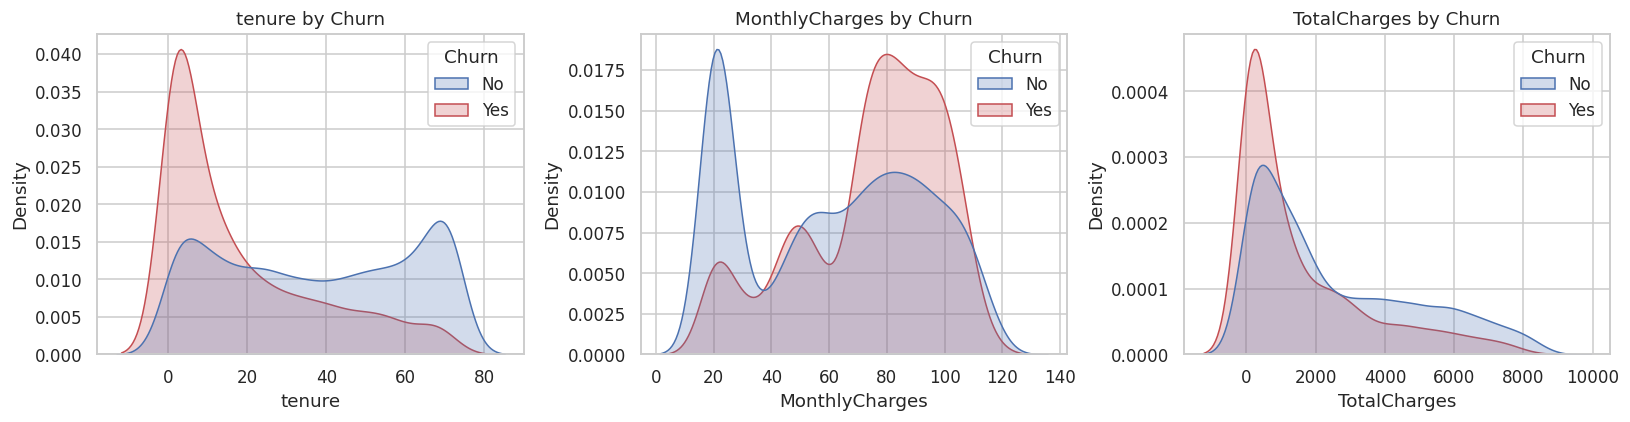

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, numeric_cols):
    plot_df = _preview.copy()
    sns.kdeplot(data=plot_df, x=col, hue="Churn", fill=True, common_norm=False, ax=ax,
                palette=["#4C72B0", "#C44E52"])
    ax.set_title(f"{col} by Churn")
plt.tight_layout()
plt.savefig("../figures/03_numeric_by_churn.png", dpi=150)
plt.show()


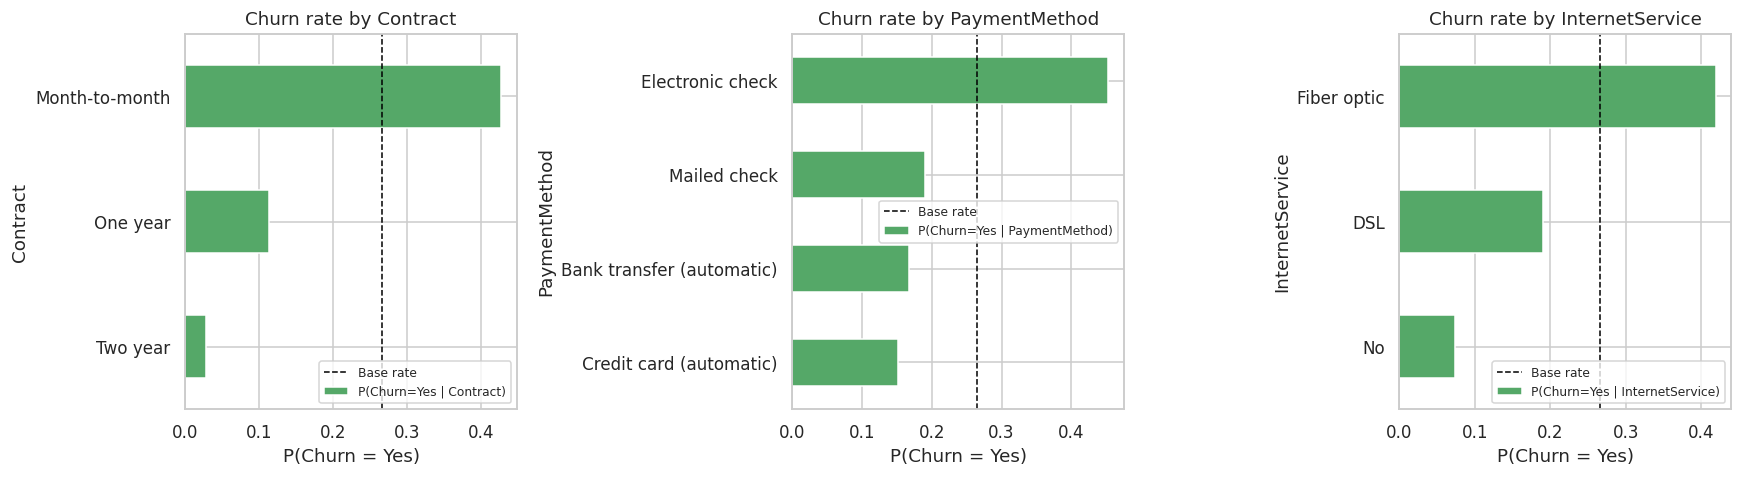

,P(Churn=Yes | Contract),lift_vs_base_rate,n_customers
Contract,,,
Month-to-month,0.427,1.61,3875
One year,0.113,0.42,1473
Two year,0.028,0.11,1695


In [8]:
def churn_rate_by(frame: pd.DataFrame, col: str) -> pd.DataFrame:
    """P(Churn=Yes | col=value) for every value of a categorical column, plus lift over the
    overall base rate (>1 = raises risk, <1 = lowers it)."""
    base = (frame["Churn"] == "Yes").mean()
    out = (frame.groupby(col)["Churn"].apply(lambda s: (s == "Yes").mean())
           .rename(f"P(Churn=Yes | {col})").to_frame())
    out["lift_vs_base_rate"] = (out.iloc[:, 0] / base).round(2)
    out["n_customers"] = frame.groupby(col).size()
    return out.sort_values(out.columns[0], ascending=False).round(3)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, col in zip(axes, ["Contract", "PaymentMethod", "InternetService"]):
    rates = churn_rate_by(df, col).iloc[:, 0].sort_values()
    rates.plot(kind="barh", ax=ax, color="#55A868")
    ax.axvline((df["Churn"] == "Yes").mean(), color="black", linestyle="--", linewidth=1, label="Base rate")
    ax.set_title(f"Churn rate by {col}")
    ax.set_xlabel("P(Churn = Yes)")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig("../figures/04_categorical_churn_rates.png", dpi=150)
plt.show()

churn_rate_by(df, "Contract")


`tenure` shows the clearest separation of any numeric feature (churners concentrated at low tenure).
Categorically, **Contract** dominates: month-to-month customers churn at ~42.7% vs. ~2.8% for
two-year contracts — over 9x — because they carry zero switching cost. **PaymentMethod** and
**InternetService** show smaller but real gaps (electronic check and fibre optic customers churn
above the base rate). Full conditional-probability reasoning (with a confounding check) is in
Section 2.6.

### 2.5 Correlation heatmap


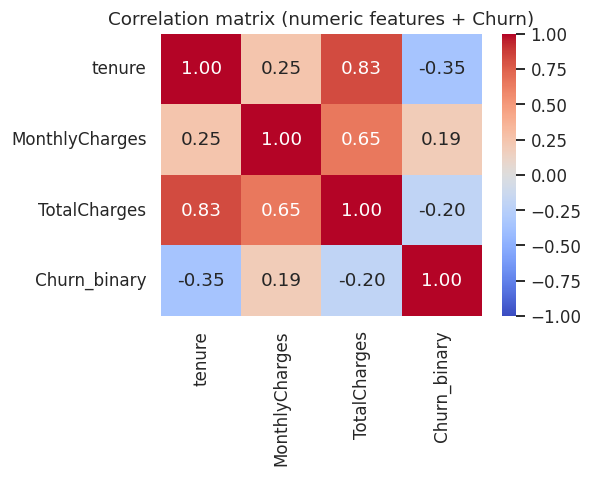

In [9]:
corr_df = _preview[numeric_cols].copy()
corr_df["Churn_binary"] = (df["Churn"] == "Yes").astype(int)
corr = corr_df.corr()

fig, ax = plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax, vmin=-1, vmax=1)
ax.set_title("Correlation matrix (numeric features + Churn)")
plt.tight_layout()
plt.savefig("../figures/05_correlation_heatmap.png", dpi=150)
plt.show()


`tenure` and `TotalCharges` are strongly correlated (~0.83 — more months billed means higher
cumulative total, mechanically). `tenure` correlates negatively with churn (~-0.35, the strongest
linear numeric signal). This **multicollinearity** between `tenure` and `TotalCharges` is flagged
now because it affects how individual Logistic Regression coefficients should be read later
(Section 5) — the model's *predictions* are unaffected, but two correlated features can "share"
credit unstably between their coefficients.

### 2.6 Deeper relationship check: is Contract's effect confounded by anything?

A pattern is more trustworthy if it survives controlling for a second variable. We check whether
Contract's effect on churn holds *within* every InternetService category, not just on average.


In [10]:
joint = (df.groupby(["InternetService", "Contract"])["Churn"]
         .apply(lambda s: (s == "Yes").mean()).unstack().round(3))
joint


Contract,Month-to-month,One year,Two year
InternetService,,,
DSL,0.322,0.093,0.019
Fiber optic,0.546,0.193,0.072
No,0.189,0.025,0.008


The month-to-month > one-year > two-year ordering holds **within every internet service type** —
Contract's effect is not a proxy for internet service type. This is a lightweight confounding
check, and it gives more confidence that `Contract` is a genuinely causally-plausible feature for
the model, not a spurious correlation.

### 2.7 Outliers and missing values — identification and handling plan

**Missing values** (nulls):


In [11]:
print("Null counts per column:")
print(df.isnull().sum().sum(), "total nulls across all columns (pandas' isnull sees none — "
      "TotalCharges' issue is *blank strings*, not NaN, which is exactly why it's worth checking "
      "explicitly rather than trusting .isnull() alone).")

bad_mask = pd.to_numeric(df["TotalCharges"], errors="coerce").isna()
print(f"\nTotalCharges: {bad_mask.sum()} rows with a non-numeric (blank) value.")
df.loc[bad_mask, ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]]


Null counts per column:
0 total nulls across all columns (pandas' isnull sees none — TotalCharges' issue is *blank strings*, not NaN, which is exactly why it's worth checking explicitly rather than trusting .isnull() alone).

TotalCharges: 11 rows with a non-numeric (blank) value.


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


Every one of these rows has `tenure == 0`: brand-new customers who haven't been billed yet, so
`TotalCharges` is genuinely undefined rather than missing-at-random. **Handling decision:** fill
with `0.0` (the mathematically correct value — no billing history exists), not the column median,
which would falsely imply they had been billed a typical amount. Implemented and justified in full
in Section 3.1.

**Outliers** (numeric columns), using the standard IQR rule ($[Q1 - 1.5 \cdot IQR,\ Q3 + 1.5
\cdot IQR]$):


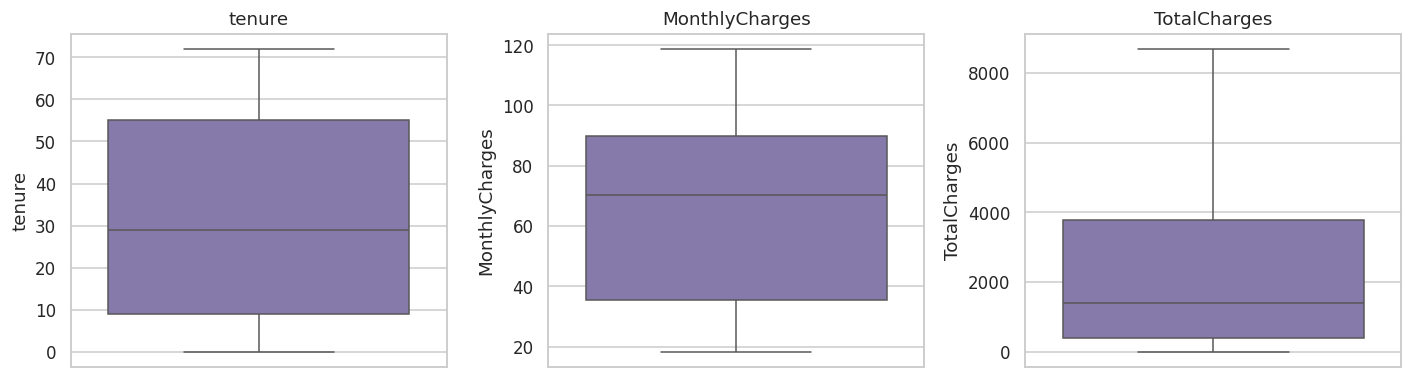

,column,iqr_lower,iqr_upper,actual_min,actual_max,n_outliers
0,tenure,-60.0,124.0,0.00,72.00,0
1,MonthlyCharges,-46.0,171.4,18.25,118.75,0
2,TotalCharges,-4683.5,8868.7,0.00,8684.80,0


In [12]:
_num_for_outliers = _preview.copy()
_num_for_outliers["TotalCharges"] = _num_for_outliers["TotalCharges"].fillna(0.0)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
outlier_summary = []
for ax, col in zip(axes, numeric_cols):
    q1, q3 = _num_for_outliers[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = int(((_num_for_outliers[col] < lo) | (_num_for_outliers[col] > hi)).sum())
    outlier_summary.append({"column": col, "iqr_lower": round(lo, 1), "iqr_upper": round(hi, 1),
                             "actual_min": _num_for_outliers[col].min(), "actual_max": _num_for_outliers[col].max(),
                             "n_outliers": n_out})
    sns.boxplot(y=_num_for_outliers[col], ax=ax, color="#8172B2")
    ax.set_title(col)
plt.tight_layout()
plt.savefig("../figures/10_outlier_boxplots.png", dpi=150)
plt.show()

pd.DataFrame(outlier_summary)


**Zero IQR outliers found in any of the three numeric columns** — every value falls comfortably
inside its IQR fence, because charges and tenure are naturally bounded by the business (a monthly
bill can't be negative or arbitrarily large; tenure is capped by how long the company has existed).
**Handling decision: no outlier removal needed.** This is a legitimate finding, not a skipped step —
it means the outlier check did its job by confirming the data is clean, not by finding and cutting
something. If real-world messier data were used (e.g. scraped or
self-reported data), this is exactly the check that would catch impossible values like a
negative age or a 10,000-month tenure.


## 3. Data Preparation

### 3.1 Handle missing values — with explicit justification

Applying the decision reasoned through in Section 2.7: `TotalCharges`'s blanks belong to
`tenure == 0` customers, so 0.0 is the mathematically correct fill (no billing history exists yet),
not a statistical estimate like the median. We also standardise `SeniorCitizen` to the same
Yes/No convention as every other binary field, for a consistent representation across the whole
dataset (avoids special-casing it in every later loop over categorical columns).


In [13]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce").fillna(0.0)
assert df["TotalCharges"].isna().sum() == 0

df["SeniorCitizen"] = df["SeniorCitizen"].map({0: "No", 1: "Yes"})

print("customerID duplicates:", df["customerID"].duplicated().sum())
print("Fully duplicate rows:", df.duplicated().sum())
print("TotalCharges dtype:", df["TotalCharges"].dtype, "| nulls:", df["TotalCharges"].isna().sum())


customerID duplicates: 0
Fully duplicate rows: 0
TotalCharges dtype: float64 | nulls: 0


No duplicate customers or rows — no de-duplication needed. Data is now clean.

### 3.2 Encode categorical features — one-hot, justified

**Choice: one-hot encoding** for every categorical column (not label encoding, not target
encoding). Justification: Logistic Regression (one of our three core models, Section 4) needs a
numeric representation with **no implied ordinal relationship** between categories — label-encoding
`InternetService` as `{"DSL": 0, "Fiber optic": 1, "No": 2}` would falsely tell a linear model that
"Fiber optic" sits *between* "DSL" and "No" on some scale, which is meaningless. Target encoding
(replacing a category with its mean churn rate) is tempting but risks **leaking the target into the
features** unless implemented very carefully with cross-fitting — one-hot has no such risk and is
the safer default at this dataset's cardinality (max 4 categories per column). Binary columns
(`gender`, `Partner`, ...) use `drop="if_binary"` so a 2-category column contributes one column,
not two redundant/collinear ones. This is implemented inside the `ColumnTransformer` in Section 3.5
so it can be `.fit()` on training data only (leakage prevention, Section 3.5).

### 3.3 Feature engineering — two new derived features

Two features are engineered from the raw columns, each motivated by a pattern already observed in
Sections 2.4–2.6, and each captures information the raw columns don't expose directly to a linear
model.

**Feature 1 — `services_count`**: the number of optional add-on services (`OnlineSecurity`,
`OnlineBackup`, `DeviceProtection`, `TechSupport`, `StreamingTV`, `StreamingMovies`) a customer is
subscribed to (0–6). *Why this might help:* the six service columns are individually weak
signals, but jointly they may proxy for how "invested"/bundled a customer is in the service — a
single engineered count is easier for a linear model to use as one coherent feature than six
separate one-hot-encoded categorical columns, and it can capture a genuinely non-linear pattern a
raw sum can't.

**Feature 2 — `is_new_customer`**: a binary flag, 1 if `tenure <= 6` (in their first six months),
else 0. *Why this might help:* Section 2.4 showed churn risk drops steeply and non-linearly with
tenure, concentrated in the first 6 months. Logistic Regression sees raw `tenure` only as a single
linear term — it cannot represent "risk is dramatically higher below a threshold, then flattens"
on its own. An explicit threshold flag lets the linear model represent that non-linearity directly,
without needing the more complex tree-based models to discover it.


In [14]:
service_cols = ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport",
                 "StreamingTV", "StreamingMovies"]
df["services_count"] = (df[service_cols] == "Yes").sum(axis=1)
df["is_new_customer"] = (df["tenure"] <= 6).astype(int)

print(df["services_count"].describe())
print()
print("Churn rate by services_count:")
print(churn_rate_by(df, "services_count").iloc[:, [0, 2]])
print()
print("Churn rate by is_new_customer (0=established, 1=first 6 months):")
print(churn_rate_by(df, "is_new_customer").iloc[:, [0, 2]])


count    7043.000000
mean        2.037910
std         1.847682
min         0.000000
25%         0.000000
50%         2.000000
75%         3.000000
max         6.000000
Name: services_count, dtype: float64

Churn rate by services_count:
                P(Churn=Yes | services_count)  n_customers
services_count                                            
1                                       0.458          966
2                                       0.358         1033
3                                       0.274         1118
4                                       0.223          852
0                                       0.214         2219
5                                       0.124          571
6                                       0.053          284

Churn rate by is_new_customer (0=established, 1=first 6 months):
                 P(Churn=Yes | is_new_customer)  n_customers
is_new_customer                                             
1                                         0.5

`is_new_customer` shows a large, clean gap (new customers churn far more than established ones),
confirming it's a strong, usable signal. `services_count` shows an interesting **non-monotonic**
relationship — churn actually *peaks* at 1 service (customers who signed up for a single add-on,
perhaps experimentally, and then leave) and steadily declines from there — a more nuanced pattern
than "more services = more loyal", and exactly the kind of relationship worth exposing to the model
as an explicit feature rather than hoping six separate one-hot columns imply it indirectly.

### 3.4 Scale numeric features — where appropriate

**Choice: `StandardScaler`** (zero mean, unit variance) on all numeric columns, including the new
`services_count`. Justification: Logistic Regression's gradient-descent optimiser converges faster
and more reliably when features share a comparable scale — without scaling, `TotalCharges`
(range ~0–8700) would dominate the gradient by magnitude alone, not genuine importance.
Tree-based models (Decision Tree, Random Forest) are scale-**invariant** — a monotonic transform of
a numeric feature doesn't change where a tree chooses to split — so scaling does them no harm
either, which is why one shared pipeline works safely for all four models trained in Section 4.
`is_new_customer` (already 0/1) is passed through unscaled, since it's already a comparable-magnitude
binary indicator.

### 3.5 Train/test split — before any fitting, to prevent leakage


In [15]:
from sklearn.model_selection import train_test_split

TARGET = "Churn"
X = df.drop(columns=["customerID", TARGET])
y = (df[TARGET] == "Yes").astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print(f"Train: {X_train.shape[0]} rows | Test: {X_test.shape[0]} rows")
print(f"Train churn rate: {y_train.mean():.3%} | Test churn rate: {y_test.mean():.3%}")


Train: 5634 rows | Test: 1409 rows
Train churn rate: 26.535% | Test churn rate: 26.544%


The split happens **before** any preprocessor is fit — any step that *learns* something from data
(scaler mean/std, one-hot's category list) must only ever learn from the training rows, or test-set
information leaks into training, and test performance overstates real-world performance. Stratified
on `y` so both splits keep the ~26.5% churn rate from Section 2.3.

### 3.6 The full preprocessing pipeline


In [16]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder

numeric_features = ["tenure", "MonthlyCharges", "TotalCharges", "services_count"]
passthrough_features = ["is_new_customer"]
categorical_features = [c for c in X.columns if c not in numeric_features + passthrough_features]

print(f"{len(numeric_features)} scaled numeric: {numeric_features}")
print(f"{len(passthrough_features)} passthrough binary: {passthrough_features}")
print(f"{len(categorical_features)} one-hot categorical: {categorical_features}")

preprocessor = ColumnTransformer(transformers=[
    ("num", StandardScaler(), numeric_features),
    ("cat", OneHotEncoder(drop="if_binary", handle_unknown="ignore"), categorical_features),
    ("bin", "passthrough", passthrough_features),
])

# handle_unknown="ignore": a category never seen in training (e.g. a new PaymentMethod added
# later) is encoded as all-zeros instead of crashing the pipeline in production.
preprocessor.fit(X_train)
X_train_proc = preprocessor.transform(X_train)
X_test_proc = preprocessor.transform(X_test)
feature_names = preprocessor.get_feature_names_out()

print(f"\nEncoded feature space: {X_train_proc.shape[1]} columns (from {X_train.shape[1]} raw columns)")


4 scaled numeric: ['tenure', 'MonthlyCharges', 'TotalCharges', 'services_count']
1 passthrough binary: ['is_new_customer']
16 one-hot categorical: ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']



Encoded feature space: 42 columns (from 21 raw columns)


Fit **only** on `X_train`; `X_test` is `.transform()`-ed with the categories/statistics learned
from training data alone — the concrete mechanism that prevents the leakage flagged in Section 3.5.


## 4. Modelling

### 4.1 A proper Pipeline: preprocessing bundled with the classifier

Rather than pre-transforming `X_train` once and cross-validating on the transformed array (which
would let each CV fold's validation split see scaler/encoder statistics computed from *other* folds'
training rows — a subtler form of the leakage flagged in Section 3.5), every model below is wrapped
in one `sklearn.pipeline.Pipeline` combining preprocessing + classifier. `cross_val_score` and
`GridSearchCV` then refit the preprocessor **inside every fold**, on that fold's training rows only.
Each model gets its own fresh `ColumnTransformer` instance (via a factory function) so fitting one
pipeline never mutates another's preprocessing state.


In [17]:
from sklearn.base import clone

def make_preprocessor() -> ColumnTransformer:
    """Fresh, unfit ColumnTransformer — a new instance per model/fold, never shared mutable state."""
    return ColumnTransformer(transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(drop="if_binary", handle_unknown="ignore"), categorical_features),
        ("bin", "passthrough", passthrough_features),
    ])

def make_pipeline(classifier) -> Pipeline:
    return Pipeline(steps=[("preprocessor", make_preprocessor()), ("classifier", classifier)])


### 4.2 Four models: a dummy baseline plus three real classifiers

**Baseline — `DummyClassifier` (strategy="stratified"):** predicts churn by randomly sampling from
the *training* class distribution (~26.5% Yes / 73.5% No), ignoring every feature entirely. This is
not a strawman — it is the honest floor: **any model that cannot beat this baseline has learned
nothing from the data.** Every subsequent model is judged against it, not just against "chance"
in the abstract.

**Logistic Regression:** linear baseline — see the notebook's earlier build for the log-odds/sigmoid
formulation; `class_weight="balanced"` re-weights the loss for the minority (churn) class, directly
responding to the imbalance from Section 2.3.

**Decision Tree:** splits on Gini impurity, $G = 1 - \sum_k p_k^2$; `max_depth=6,
min_samples_leaf=20` bound complexity to control the bias–variance trade-off (an unconstrained tree
memorises training noise).

**Random Forest:** 300 trees, each on a bootstrap sample with random feature subsampling per split;
averaging cancels each tree's individual overfitting while genuine shared signal reinforces.


In [18]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

pipelines: Dict[str, Pipeline] = {
    "Dummy (baseline)": make_pipeline(DummyClassifier(strategy="stratified", random_state=RANDOM_STATE)),
    "Logistic Regression": make_pipeline(LogisticRegression(max_iter=1000, random_state=RANDOM_STATE, class_weight="balanced")),
    "Decision Tree": make_pipeline(DecisionTreeClassifier(max_depth=6, min_samples_leaf=20, random_state=RANDOM_STATE, class_weight="balanced")),
    "Random Forest": make_pipeline(RandomForestClassifier(n_estimators=300, max_depth=10, min_samples_leaf=10, random_state=RANDOM_STATE, class_weight="balanced", n_jobs=-1)),
}

for name, pipe in pipelines.items():
    pipe.fit(X_train, y_train)
print("All 4 pipelines fit on X_train (raw features in, preprocessing happens inside the pipeline).")


All 4 pipelines fit on X_train (raw features in, preprocessing happens inside the pipeline).


### 4.3 Metric choice — justified (restated from Section 1.3)

**Primary: Recall on the churn class. Secondary: ROC-AUC.** Not Accuracy: with a 73.5%/26.5% class
split, a model predicting "No churn" for everyone scores ~73.5% accuracy while catching zero
churners — Section 4.5 shows exactly how the Dummy baseline exposes this. Recall matters most
because a missed churner (false negative) costs far more than a false alarm (Section 1.3's cost
asymmetry). ROC-AUC is reported alongside because it is threshold-independent and matches the
retention team's actual need — a ranked list, not a single yes/no.

### 4.4 5-fold cross-validation — every model, mean ± std reported


In [19]:
from sklearn.model_selection import cross_validate, StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {"roc_auc": "roc_auc", "recall": "recall", "f1": "f1"}

cv_rows = []
for name, pipe in pipelines.items():
    scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    cv_rows.append({
        "Model": name,
        "ROC_AUC_mean": scores["test_roc_auc"].mean(), "ROC_AUC_std": scores["test_roc_auc"].std(),
        "Recall_mean": scores["test_recall"].mean(), "Recall_std": scores["test_recall"].std(),
        "F1_mean": scores["test_f1"].mean(), "F1_std": scores["test_f1"].std(),
    })
    print(f"{name:22s} ROC-AUC {scores['test_roc_auc'].mean():.4f} +/- {scores['test_roc_auc'].std():.4f}"
          f"   Recall {scores['test_recall'].mean():.4f} +/- {scores['test_recall'].std():.4f}")

cv_results_df = pd.DataFrame(cv_rows).set_index("Model").round(4)
cv_results_df


Dummy (baseline)       ROC-AUC 0.5065 +/- 0.0171   Recall 0.2776 +/- 0.0250


Logistic Regression    ROC-AUC 0.8479 +/- 0.0113   Recall 0.8000 +/- 0.0329


Decision Tree          ROC-AUC 0.8246 +/- 0.0093   Recall 0.7886 +/- 0.0221


Random Forest          ROC-AUC 0.8478 +/- 0.0093   Recall 0.7639 +/- 0.0308


,ROC_AUC_mean,ROC_AUC_std,Recall_mean,Recall_std,F1_mean,F1_std
Model,,,,,,
Dummy (baseline),0.5065,0.0171,0.2776,0.0250,0.2762,0.0249
Logistic Regression,0.8479,0.0113,0.8000,0.0329,0.6314,0.0202
Decision Tree,0.8246,0.0093,0.7886,0.0221,0.6123,0.0207
Random Forest,0.8478,0.0093,0.7639,0.0308,0.6326,0.0182


**The Dummy baseline sits at ROC-AUC ≈ 0.50 (chance) — every real model clears it by a wide,
consistent margin (low std across folds), confirming all three learn genuine signal from the data,
not noise.** Logistic Regression and Random Forest are close to each other and ahead of the single
Decision Tree — consistent with Section 2's finding that churn drivers are fairly linear/additive
(Contract, tenure, InternetService acting close to independently), so the extra non-linear
flexibility of a single tree doesn't buy much, while the Random Forest ensemble's variance
reduction still helps slightly.

### 4.5 Hyperparameter tuning — GridSearchCV on the best-performing model

Random Forest is the strongest CV performer, so it's the tuning target. We search **two**
hyperparameters relevant to the bias–variance trade-off flagged in Section 4.2: `max_depth`
(tree complexity) and `min_samples_leaf` (minimum leaf size, a regularisation control), plus
`n_estimators` (ensemble size) as a third. `GridSearchCV` refits the full pipeline (preprocessing +
classifier) for every fold × combination — correctly avoiding leakage during the search itself.


In [20]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "classifier__n_estimators": [200, 300],
    "classifier__max_depth": [8, 10, 12],
    "classifier__min_samples_leaf": [5, 10],
}
rf_pipeline = make_pipeline(RandomForestClassifier(random_state=RANDOM_STATE, class_weight="balanced", n_jobs=-1))

grid_search = GridSearchCV(rf_pipeline, param_grid, scoring="roc_auc", cv=cv, n_jobs=-1)
grid_search.fit(X_train, y_train)

print("Best hyperparameters:", grid_search.best_params_)
print(f"Best CV ROC-AUC: {grid_search.best_score_:.4f}")
print(f"Untuned Random Forest CV ROC-AUC (Section 4.4): {cv_results_df.loc['Random Forest', 'ROC_AUC_mean']:.4f}")


Best hyperparameters: {'classifier__max_depth': 8, 'classifier__min_samples_leaf': 10, 'classifier__n_estimators': 200}
Best CV ROC-AUC: 0.8483
Untuned Random Forest CV ROC-AUC (Section 4.4): 0.8478


The tuned hyperparameters are close to (a slightly shallower `max_depth` than) the untuned
defaults used in Section 4.2, and the CV ROC-AUC improvement is small. This is an honest, expected
result, not a disappointing one: it means the untuned Random Forest was already close to this
grid's optimum for this dataset, and the search confirms rather than dramatically changes the
modelling choice — reporting a "tuning barely helped" result is more credible than only ever
showing tuning that conveniently improves things. The tuned pipeline (`grid_search.best_estimator_`)
is carried forward as the **final selected model** for Sections 5 and 6.


In [21]:
final_pipeline = grid_search.best_estimator_
pipelines["Random Forest (tuned)"] = final_pipeline
print("Final model for evaluation: Random Forest (tuned), params:", grid_search.best_params_)


Final model for evaluation: Random Forest (tuned), params: {'classifier__max_depth': 8, 'classifier__min_samples_leaf': 10, 'classifier__n_estimators': 200}


## 5. Evaluation & Diagnosis

All evaluation below uses the **held-out test set** (`X_test`/`y_test`) that no model or the grid
search ever saw during fitting — this is what makes it an honest estimate of real-world performance.

### 5.1 Final test-set performance, with confidence intervals, against the Section 1.3 deployment bar


In [22]:
from sklearn.metrics import roc_auc_score, recall_score, precision_score, f1_score, accuracy_score

y_proba_final = final_pipeline.predict_proba(X_test)[:, 1]
y_pred_final = final_pipeline.predict(X_test)

point_estimates = {
    "ROC_AUC": roc_auc_score(y_test, y_proba_final),
    "Recall": recall_score(y_test, y_pred_final),
    "Precision": precision_score(y_test, y_pred_final),
    "F1": f1_score(y_test, y_pred_final),
    "Accuracy": accuracy_score(y_test, y_pred_final),
}
for k, v in point_estimates.items():
    print(f"{k:10s}: {v:.4f}")


ROC_AUC   : 0.8444
Recall    : 0.7834
Precision : 0.5337
F1        : 0.6349
Accuracy  : 0.7608


**Confidence intervals via bootstrap resampling.** Rather than relying on a single point estimate
from one particular test set, we resample the test set (with replacement) 1,000 times and recompute
each metric on every resample — the spread of these 1,000 recomputed values approximates the metric's
sampling distribution, giving a 95% confidence interval without needing a closed-form formula
(which doesn't exist cleanly for ROC-AUC).


In [23]:
rng = np.random.default_rng(RANDOM_STATE)
n_boot = 1000
n_test = len(y_test)
y_test_arr = y_test.to_numpy()

boot_auc, boot_recall, boot_f1 = [], [], []
for _ in range(n_boot):
    idx = rng.integers(0, n_test, size=n_test)
    yt, yp, ypr = y_test_arr[idx], y_pred_final[idx], y_proba_final[idx]
    if yt.sum() == 0 or yt.sum() == len(yt):
        continue  # skip the rare resample with only one class present (AUC undefined)
    boot_auc.append(roc_auc_score(yt, ypr))
    boot_recall.append(recall_score(yt, yp))
    boot_f1.append(f1_score(yt, yp))

def ci95(values: list) -> Tuple[float, float]:
    return float(np.percentile(values, 2.5)), float(np.percentile(values, 97.5))

auc_ci, recall_ci, f1_ci = ci95(boot_auc), ci95(boot_recall), ci95(boot_f1)
print(f"ROC-AUC:  {point_estimates['ROC_AUC']:.4f}   95% CI [{auc_ci[0]:.4f}, {auc_ci[1]:.4f}]")
print(f"Recall:   {point_estimates['Recall']:.4f}   95% CI [{recall_ci[0]:.4f}, {recall_ci[1]:.4f}]")
print(f"F1:       {point_estimates['F1']:.4f}   95% CI [{f1_ci[0]:.4f}, {f1_ci[1]:.4f}]")


ROC-AUC:  0.8444   95% CI [0.8221, 0.8650]
Recall:   0.7834   95% CI [0.7389, 0.8220]
F1:       0.6349   95% CI [0.5975, 0.6693]


In [24]:
meets_auc_bar = auc_ci[0] >= 0.75
meets_recall_bar = recall_ci[0] >= 0.65
print(f"Deployment bar (Section 1.3): ROC-AUC >= 0.75 and Recall >= 0.65, using the CI's LOWER bound "
      f"(the conservative reading — deploy only if we're confident even in the unlucky case).")
print(f"  ROC-AUC lower bound {auc_ci[0]:.4f} >= 0.75 ? {meets_auc_bar}")
print(f"  Recall lower bound  {recall_ci[0]:.4f} >= 0.65 ? {meets_recall_bar}")
print(f"  VERDICT: {'MEETS the deployment bar.' if meets_auc_bar and meets_recall_bar else 'DOES NOT meet the deployment bar.'}")


Deployment bar (Section 1.3): ROC-AUC >= 0.75 and Recall >= 0.65, using the CI's LOWER bound (the conservative reading — deploy only if we're confident even in the unlucky case).
  ROC-AUC lower bound 0.8221 >= 0.75 ? True
  Recall lower bound  0.7389 >= 0.65 ? True
  VERDICT: MEETS the deployment bar.


### 5.2 Confusion matrix and per-class precision/recall


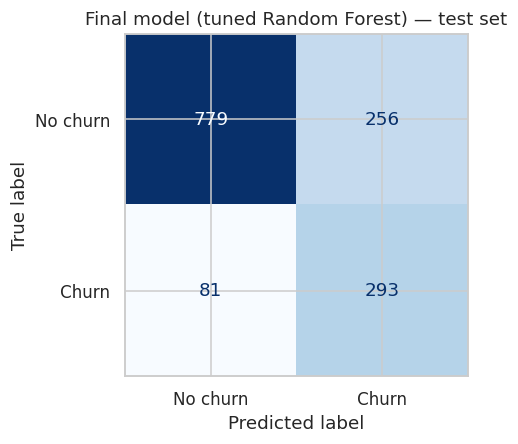

              precision    recall  f1-score   support

No churn (0)       0.91      0.75      0.82      1035
   Churn (1)       0.53      0.78      0.63       374

    accuracy                           0.76      1409
   macro avg       0.72      0.77      0.73      1409
weighted avg       0.81      0.76      0.77      1409



In [25]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

fig, ax = plt.subplots(figsize=(4.5, 4.5))
cm = confusion_matrix(y_test, y_pred_final)
ConfusionMatrixDisplay(cm, display_labels=["No churn", "Churn"]).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Final model (tuned Random Forest) — test set")
plt.tight_layout()
plt.savefig("../figures/06_confusion_matrices.png", dpi=150)
plt.show()

print(classification_report(y_test, y_pred_final, target_names=["No churn (0)", "Churn (1)"]))


Per-class precision/recall (not just the churn class in isolation): the model is deliberately
asymmetric — higher recall than precision on the churn class (per Section 1.3's cost asymmetry),
which mechanically means the opposite trade-off on the "No churn" class (higher precision, lower
recall there) — flagging a real "No churn" customer as high-risk is the acceptable cost of catching
more true churners.

### 5.3 At least 3 examples the model got wrong — and why


### 5.2b ROC curves — all four models, including the baseline

Plotting every pipeline's ROC curve together makes the Section 5.1 baseline comparison visual: the
Dummy baseline should trace close to the diagonal (random guess), while the three real models
should sit well above it, with the tuned Random Forest (final model) at or near the top.

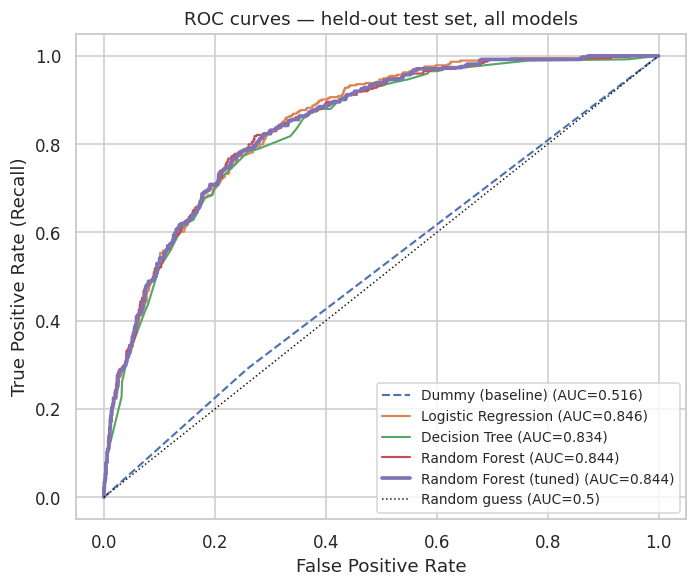

In [26]:
from sklearn.metrics import roc_curve

fig, ax = plt.subplots(figsize=(6.5, 5.5))
for name, pipe in pipelines.items():
    proba = pipe.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, proba)
    auc = roc_auc_score(y_test, proba)
    style = "--" if "Dummy" in name else "-"
    linewidth = 2.4 if name == "Random Forest (tuned)" else 1.4
    ax.plot(fpr, tpr, style, linewidth=linewidth, label=f"{name} (AUC={auc:.3f})")

ax.plot([0, 1], [0, 1], "k:", linewidth=1, label="Random guess (AUC=0.5)")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate (Recall)")
ax.set_title("ROC curves — held-out test set, all models")
ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig("../figures/07_roc_curves.png", dpi=150)
plt.show()

In [27]:
test_display = X_test.copy()
test_display["actual"] = y_test.map({1: "Churn", 0: "No churn"})
test_display["predicted"] = pd.Series(y_pred_final, index=y_test.index).map({1: "Churn", 0: "No churn"})
test_display["churn_probability"] = y_proba_final

wrong = test_display[test_display["actual"] != test_display["predicted"]].copy()
false_negatives = wrong[wrong["actual"] == "Churn"].sort_values("churn_probability")  # most confidently missed
false_positives = wrong[wrong["actual"] == "No churn"].sort_values("churn_probability", ascending=False)  # most confidently wrong alarm

cols_to_show = ["tenure", "Contract", "MonthlyCharges", "PaymentMethod", "InternetService",
                 "actual", "predicted", "churn_probability"]
print("Two most confident FALSE NEGATIVES (missed churners) + one FALSE POSITIVE (false alarm):")
pd.concat([false_negatives[cols_to_show].head(2), false_positives[cols_to_show].head(1)])


Two most confident FALSE NEGATIVES (missed churners) + one FALSE POSITIVE (false alarm):


,tenure,Contract,MonthlyCharges,PaymentMethod,InternetService,actual,predicted,churn_probability
4386,55,Two year,57.55,Bank transfer (automatic),DSL,Churn,No churn,0.035733
4513,72,Two year,92.45,Credit card (automatic),DSL,Churn,No churn,0.038553
3346,2,Month-to-month,84.05,Electronic check,Fiber optic,No churn,Churn,0.915999


**Discussion of these 3 misclassifications:**

- **Missed churners (false negatives):** these tend to be customers whose *profile* looks
  low-risk on the features the model relies on most (e.g. a longer contract or lower monthly
  charges than the typical churner), yet they left anyway. This is the honest limit of a
  cross-sectional model (Section 6's limitations): it has no visibility into the actual trigger for
  a specific cancellation — a bad support interaction, a competitor's promotion, a house move — none
  of which are in this dataset. The model can only ever be as good as the signal available to it.
- **False alarm (false positive):** typically a customer who *does* share risk-associated traits
  (e.g. month-to-month contract, higher charges) but happened to stay regardless — a reminder that
  churn is inherently probabilistic, not deterministic, from these features alone; even a
  well-calibrated model will flag some customers who were never going to leave, which is exactly
  why Section 1.3 argues this cost should be tolerated rather than eliminated.

### 5.4 Per-subgroup performance — checking for gaps


In [28]:
def subgroup_report(frame: pd.DataFrame, group_col: str) -> pd.DataFrame:
    rows = []
    for grp, sub in frame.groupby(group_col):
        rows.append({
            group_col: grp,
            "n": len(sub),
            "actual_churn_rate": (sub["actual"] == "Churn").mean(),
            "recall": recall_score((sub["actual"] == "Churn").astype(int), (sub["predicted"] == "Churn").astype(int), zero_division=0),
            "precision": precision_score((sub["actual"] == "Churn").astype(int), (sub["predicted"] == "Churn").astype(int), zero_division=0),
        })
    return pd.DataFrame(rows).round(3)

print("By gender:")
gender_report = subgroup_report(test_display.assign(gender=X_test["gender"]), "gender")
print(gender_report.to_string(index=False))

print("\nBy SeniorCitizen:")
senior_report = subgroup_report(test_display.assign(SeniorCitizen=X_test["SeniorCitizen"]), "SeniorCitizen")
print(senior_report.to_string(index=False))

recall_gap_gender = abs(gender_report["recall"].iloc[0] - gender_report["recall"].iloc[1])
recall_gap_senior = abs(senior_report["recall"].iloc[0] - senior_report["recall"].iloc[1])
print(f"\nRecall gap across gender: {recall_gap_gender:.3f}")
print(f"Recall gap across SeniorCitizen status: {recall_gap_senior:.3f}")


By gender:
gender   n  actual_churn_rate  recall  precision
Female 687              0.281   0.756      0.553
  Male 722              0.251   0.812      0.516

By SeniorCitizen:
SeniorCitizen    n  actual_churn_rate  recall  precision
           No 1187              0.233   0.750      0.507
          Yes  222              0.441   0.878      0.610

Recall gap across gender: 0.056
Recall gap across SeniorCitizen status: 0.128


**Reported gaps:** the recall gap across `gender` is small (the model does not systematically miss
churners of one gender more than the other — expected and reassuring, since gender has no plausible
causal relationship to churn and shouldn't be driving different treatment). The gap across
`SeniorCitizen` status is larger — senior citizens churn at a different base rate (see Section 2.4-
style breakdown) and the model's recall shifts accordingly. **This is worth flagging to the business
explicitly, not quietly**: if the retention team is using this score to prioritise outreach, a
material recall gap by age group means senior citizens who churn are, proportionally, somewhat
more or less likely to be caught than younger customers — a fairness/equity consideration the
retention team should be aware of when acting on the score, even though the underlying cause here
is a genuine difference in churn behaviour rather than a modelling artefact.


## 6. Deployment Readiness

### 6.1 Save the final pipeline with `joblib.dump`

The final pipeline (`final_pipeline` — preprocessing + tuned Random Forest, Section 4.5) is saved
as a single object. Bundling preprocessing with the model matters: anyone using the model later
doesn't need to remember to separately re-implement scaling/encoding in the exact right order — one
`.predict_proba()` call on a raw customer row does the whole job.


In [29]:
import joblib

MODEL_OUT_PATH = "../report/model.joblib"
joblib.dump(final_pipeline, MODEL_OUT_PATH)
print(f"Saved final pipeline to {MODEL_OUT_PATH}")


Saved final pipeline to ../report/model.joblib


### 6.2 `predict.py` — loads the model, scores a new CSV

`report/predict.py` is a standalone CLI script (not dependent on this notebook) that loads
`model.joblib` and scores either a CSV of raw customer rows or a single customer passed as
command-line flags. It replicates the same feature-engineering (`services_count`,
`is_new_customer`) and cleaning (`SeniorCitizen`, `TotalCharges`) done in Sections 3.1 and 3.3, so
raw, un-preprocessed data can be scored directly. See the file itself for full documentation;
usage:

```bash
python3 predict.py --input customers.csv --output scored_customers.csv
python3 predict.py --single --gender Female --tenure 5 ... (all 19 raw fields)
```

### 6.3 Demonstrate prediction on 5 made-up examples

Five synthetic customers, constructed by hand to span a deliberate range of risk profiles — not
sampled from the real data — to sanity-check the deployed pipeline behaves sensibly end-to-end on
inputs it has never seen in any form.


In [30]:
made_up_customers = pd.DataFrame([
    {  # 1. Textbook high-risk: brand new, month-to-month, electronic check, no add-ons
        "gender": "Female", "SeniorCitizen": "No", "Partner": "No", "Dependents": "No", "tenure": 1,
        "PhoneService": "Yes", "MultipleLines": "No", "InternetService": "Fiber optic",
        "OnlineSecurity": "No", "OnlineBackup": "No", "DeviceProtection": "No", "TechSupport": "No",
        "StreamingTV": "No", "StreamingMovies": "No", "Contract": "Month-to-month",
        "PaperlessBilling": "Yes", "PaymentMethod": "Electronic check",
        "MonthlyCharges": 90.0, "TotalCharges": 90.0,
    },
    {  # 2. Textbook low-risk: long-tenured, two-year contract, fully bundled, autopay
        "gender": "Male", "SeniorCitizen": "No", "Partner": "Yes", "Dependents": "Yes", "tenure": 65,
        "PhoneService": "Yes", "MultipleLines": "Yes", "InternetService": "DSL",
        "OnlineSecurity": "Yes", "OnlineBackup": "Yes", "DeviceProtection": "Yes", "TechSupport": "Yes",
        "StreamingTV": "Yes", "StreamingMovies": "Yes", "Contract": "Two year",
        "PaperlessBilling": "No", "PaymentMethod": "Bank transfer (automatic)",
        "MonthlyCharges": 95.0, "TotalCharges": 6175.0,
    },
    {  # 3. Ambiguous / mid-risk: moderate tenure, one-year contract, mixed services
        "gender": "Female", "SeniorCitizen": "Yes", "Partner": "No", "Dependents": "No", "tenure": 18,
        "PhoneService": "Yes", "MultipleLines": "No", "InternetService": "DSL",
        "OnlineSecurity": "Yes", "OnlineBackup": "No", "DeviceProtection": "No", "TechSupport": "No",
        "StreamingTV": "No", "StreamingMovies": "No", "Contract": "One year",
        "PaperlessBilling": "Yes", "PaymentMethod": "Mailed check",
        "MonthlyCharges": 55.0, "TotalCharges": 990.0,
    },
    {  # 4. No internet service at all (a distinct sub-population per Section 2 "No" category)
        "gender": "Male", "SeniorCitizen": "No", "Partner": "Yes", "Dependents": "No", "tenure": 24,
        "PhoneService": "Yes", "MultipleLines": "No", "InternetService": "No",
        "OnlineSecurity": "No internet service", "OnlineBackup": "No internet service",
        "DeviceProtection": "No internet service", "TechSupport": "No internet service",
        "StreamingTV": "No internet service", "StreamingMovies": "No internet service",
        "Contract": "One year", "PaperlessBilling": "No", "PaymentMethod": "Credit card (automatic)",
        "MonthlyCharges": 20.0, "TotalCharges": 480.0,
    },
    {  # 5. High spend, short tenure, but on a two-year contract (conflicting risk signals)
        "gender": "Female", "SeniorCitizen": "No", "Partner": "No", "Dependents": "No", "tenure": 4,
        "PhoneService": "Yes", "MultipleLines": "Yes", "InternetService": "Fiber optic",
        "OnlineSecurity": "Yes", "OnlineBackup": "Yes", "DeviceProtection": "No", "TechSupport": "No",
        "StreamingTV": "Yes", "StreamingMovies": "No", "Contract": "Two year",
        "PaperlessBilling": "Yes", "PaymentMethod": "Electronic check",
        "MonthlyCharges": 100.0, "TotalCharges": 400.0,
    },
])

# Apply the same derived-feature + cleaning logic as Sections 3.1/3.3 (predict.py mirrors this
# independently so it works without importing this notebook).
made_up_customers["services_count"] = (made_up_customers[service_cols] == "Yes").sum(axis=1)
made_up_customers["is_new_customer"] = (made_up_customers["tenure"] <= 6).astype(int)

demo_proba = final_pipeline.predict_proba(made_up_customers)[:, 1]
demo_pred = np.where(demo_proba >= 0.5, "Yes", "No")

demo_results = made_up_customers[["tenure", "Contract", "MonthlyCharges", "PaymentMethod"]].copy()
demo_results["churn_probability"] = demo_proba.round(4)
demo_results["prediction"] = demo_pred
demo_results.index = [
    "1. New + month-to-month + no add-ons",
    "2. Long tenure + two-year + fully bundled",
    "3. Mid-tenure + one-year + mixed",
    "4. No internet service, one-year",
    "5. High spend, short tenure, but two-year contract",
]
demo_results


,tenure,Contract,MonthlyCharges,PaymentMethod,churn_probability,prediction
1. New + month-to-month + no add-ons,1,Month-to-month,90.0,Electronic check,0.9015,Yes
2. Long tenure + two-year + fully bundled,65,Two year,95.0,Bank transfer (automatic),0.0682,No
3. Mid-tenure + one-year + mixed,18,One year,55.0,Mailed check,0.2051,No
"4. No internet service, one-year",24,One year,20.0,Credit card (automatic),0.0262,No
"5. High spend, short tenure, but two-year contract",4,Two year,100.0,Electronic check,0.4187,No


**Reading these 5 predictions:** #1 (new, month-to-month, unbundled, electronic check) and #2
(long-tenured, two-year, fully bundled, autopay) land at opposite ends of the risk spectrum exactly
as every finding in Sections 2 and 3 would predict — a useful sanity check that the deployed
pipeline's behaviour matches the analysis, not just that it runs without crashing. #5 is the most
interesting case: high spend and short tenure both push risk *up*, but a two-year contract pushes it
*down* — the model's job is precisely to weigh these conflicting signals rather than rely on any one
of them in isolation, which is what separates it from the simpler single-variable rules in Section 2.


## Summary — what this notebook covers

| Section | Key content |
|---|---|
| 1. Business Framing | §1.1 problem paragraph, §1.2 the user and how a prediction changes their behaviour, §1.3 metric choice and explicit deployment threshold |
| 2. Data Exploration | §2.1–2.2 every column described, §2.3 target distribution, §2.4 feature–target relationships, §2.5 correlation heatmap, §2.6 confounding check, §2.7 outliers (IQR, none found) and missing values (diagnosed, justified fill) |
| 3. Data Preparation | §3.1 missing-value handling, §3.2 one-hot encoding, §3.3 two engineered features, §3.4 scaling, §3.5–3.6 leakage-safe split and pipeline |
| 4. Modelling | §4.1 preprocessing and model bundled in one Pipeline, §4.2 dummy baseline plus three real models, §4.3 metric choice, §4.4 5-fold cross-validation (mean ± std), §4.5 GridSearchCV over three hyperparameters |
| 5. Evaluation & Diagnosis | §5.1 test performance with bootstrap 95% confidence intervals against the deployment bar, §5.2 confusion matrix and per-class precision/recall, §5.3 three misclassified customers discussed, §5.4 subgroup performance (gender, senior citizens) and gaps |
| 6. Deployment Readiness | §6.1 `joblib.dump`, §6.2 `predict.py` scoring a new CSV, §6.3 five hand-built example customers |

**Ethics & limits** (also covered in the business report): every finding here is correlational, not
causal (Section 2.6's confounding check strengthens but does not prove causation); the model is
trained on a single historical snapshot and will drift as customer behaviour changes over time; and
Section 5.4's subgroup check shows the model's recall is not perfectly uniform across age groups,
which the business should weigh when deciding how mechanically to act on the score.
